# Denon CIP data review

This notebook reads every `.xlsx` file in `datasets/`, cleans the exported report layout, and compares CIP cycles across lines, objects, recipes, activities, and steps.

The volume figures are flow-based estimates. They are useful for comparing runs, but they are not a mass balance or a measured drain volume.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
DATA_DIR = Path('datasets')
REQUIRED = [
    'Date Time', 'Object', 'Recipe', 'Activity', 'Step',
    'Time In Seconds', 'Temp SP', 'Return Temp', 'Supply Flow',
    'Return Flow', 'Min Return Flow SP', 'Return Conducivity',
    'Caustic SP', 'Acid SP', 'Final Rinse Cond. SP', 'Flip'
]
NUMERIC = [c for c in REQUIRED if c not in {'Date Time', 'Object', 'Recipe', 'Activity', 'Step'}]

## Load and clean the exported reports

The source files put the table header on Excel row 14. The blank/unit rows are removed by requiring a timestamp. The line name is read from the report header rather than inferred from the filename.

In [2]:
def line_from_report(path):
    raw = pd.read_excel(path, header=None, nrows=10)
    text = ' '.join(raw.astype(str).fillna('').stack())
    match = re.search(r'Line\s*:\s*([^ ]+)', text, flags=re.I)
    return match.group(1) if match else path.stem

def read_report(path):
    df = pd.read_excel(path, sheet_name=0, header=13)
    missing = [c for c in REQUIRED if c not in df.columns]
    if missing:
        raise ValueError(f'{path.name} is missing columns: {missing}')
    df = df[REQUIRED].copy()
    df['Date Time'] = pd.to_datetime(df['Date Time'], errors='coerce')
    df = df[df['Date Time'].notna()].copy()
    for col in NUMERIC:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df['Line'] = line_from_report(path)
    df['Source File'] = path.name
    return df

files = sorted(DATA_DIR.glob('*.xlsx'))
if not files:
    raise FileNotFoundError(f'No Excel files found in {DATA_DIR.resolve()}')
data = pd.concat([read_report(p) for p in files], ignore_index=True)
data = data.sort_values(['Line', 'Object', 'Date Time']).reset_index(drop=True)

assert set(REQUIRED).issubset(data.columns)
print(f'Loaded {len(files)} files and {len(data):,} timestamped rows.')
print('Lines:', sorted(data['Line'].dropna().unique()))
data.head()

Loaded 4 files and 38,943 timestamped rows.
Lines: ['M01W01', 'M01W02', 'M11W01', 'M11W02']


,Date Time,Object,Recipe,Activity,Step,Time In Seconds,Temp SP,Return Temp,Supply Flow,Return Flow,Min Return Flow SP,Return Conducivity,Caustic SP,Acid SP,Final Rinse Cond. SP,Flip,Line,Source File
0,2026-07-02 19:38:06.703,C01C01-RMT Tank-1,Caustic,Pre Rinse,Fill To Tank,9,1,41.29,-62.50,-50.00,12600,0.90,55,65,2.00,0.00,M01W01,CIP_Log-202607261035.xlsx
1,2026-07-02 19:39:06.653,C01C01-RMT Tank-1,Caustic,Pre Rinse,Fill To Tank,69,1,41.22,"12,809.38","11,865.00",12600,0.90,55,65,2.00,0.00,M01W01,CIP_Log-202607261035.xlsx
2,2026-07-02 19:40:06.703,C01C01-RMT Tank-1,Caustic,Pre Rinse,Fill Circuit,129,1,25.16,"11,900.00","6,720.00",12600,1.23,55,65,2.00,0.00,M01W01,CIP_Log-202607261035.xlsx
3,2026-07-02 19:41:06.653,C01C01-RMT Tank-1,Caustic,Pre Rinse,Circulation,189,1,25.99,"2,003.12","-1,045.00",12600,1.34,55,65,2.00,1.00,M01W01,CIP_Log-202607261035.xlsx
4,2026-07-02 19:42:06.703,C01C01-RMT Tank-1,Caustic,Pre Rinse,Circulation,249,1,27.36,-62.50,-50.00,12600,1.34,55,65,2.00,1.00,M01W01,CIP_Log-202607261035.xlsx


In [9]:
data['Step'].unique()

array(['Fill To Tank', 'Fill Circuit', 'Circulation', 'Front Mix Zone',
       'Start Next Activity', 'Empty Tank', 'Heating'], dtype=object)

In [3]:
data.tail()

,Date Time,Object,Recipe,Activity,Step,Time In Seconds,Temp SP,Return Temp,Supply Flow,Return Flow,Min Return Flow SP,Return Conducivity,Caustic SP,Acid SP,Final Rinse Cond. SP,Flip,Line,Source File
38938,2026-07-26 06:34:06.703,C11W03-CPT To EVA BTD-1,Caustic Acid,Final Rinse,Circulation,3993,1,73.71,"24,787.50","24,759.38",24750,0.24,55,65,2.10,0.00,M11W02,CIP_Log-202607261035 (2).xlsx
38939,2026-07-26 06:35:06.653,C11W03-CPT To EVA BTD-1,Caustic Acid,Final Rinse,Circulation,4052,1,36.94,"25,043.75","25,050.00",24750,0.44,55,65,2.10,0.00,M11W02,CIP_Log-202607261035 (2).xlsx
38940,2026-07-26 06:36:06.703,C11W03-CPT To EVA BTD-1,Caustic Acid,Final Rinse,Circulation,4113,1,35.79,"25,006.25","25,012.50",24750,0.42,55,65,2.10,0.00,M11W02,CIP_Log-202607261035 (2).xlsx
38941,2026-07-26 06:37:06.703,C11W03-CPT To EVA BTD-1,Caustic Acid,Final Rinse,Circulation,4173,1,35.55,"24,965.63","24,887.50",24750,0.44,55,65,2.10,1.00,M11W02,CIP_Log-202607261035 (2).xlsx
38942,2026-07-26 06:38:06.653,C11W03-CPT To EVA BTD-1,Caustic Acid,Final Rinse,Circulation,4233,1,35.48,"25,215.63","25,181.25",24750,0.44,55,65,2.10,0.00,M11W02,CIP_Log-202607261035 (2).xlsx


In [4]:
overview = (data.groupby('Line', dropna=False)
    .agg(rows=('Date Time', 'size'), objects=('Object', 'nunique'), recipes=('Recipe', 'nunique'),
         first_seen=('Date Time', 'min'), last_seen=('Date Time', 'max'))
    .sort_index())
overview

,rows,objects,recipes,first_seen,last_seen
Line,,,,,
M01W01,5742,5,4,2026-07-01 10:36:06.703,2026-07-26 09:05:06.653
M01W02,10290,1,1,2026-07-01 22:27:06.703,2026-07-26 03:56:06.703
M11W01,11539,12,3,2026-07-01 16:27:06.703,2026-07-26 09:22:06.653
M11W02,11372,11,3,2026-07-01 16:27:06.703,2026-07-26 09:47:06.653


## Data quality and operating ranges

These checks make bad readings visible. Negative flows, missing values, and long timestamp gaps should be reviewed with the controls engineer before using the volume estimates for savings calculations.

In [5]:
quality = pd.DataFrame({
    'missing': data[REQUIRED].isna().sum(),
    'missing_pct': (data[REQUIRED].isna().mean() * 100).round(2),
    'unique': data[REQUIRED].nunique(dropna=True),
})
quality

# Simple sensor flags. Thresholds are review flags, not acceptance limits.
flags = {
    'negative_supply_flow': int((data['Supply Flow'] < 0).sum()),
    'negative_return_flow': int((data['Return Flow'] < 0).sum()),
    'return_below_min_flow_sp': int((data['Return Flow'] < data['Min Return Flow SP']).sum()),
    'return_temp_below_temp_sp': int((data['Return Temp'] < data['Temp SP']).sum()),
}
flags

{'negative_supply_flow': 6433,
 'negative_return_flow': 6027,
 'return_below_min_flow_sp': 16215,
 'return_temp_below_temp_sp': 5583}

In [6]:
# Add elapsed time between readings within an object/recipe. Do not bridge long gaps.
group = ['Line', 'Object', 'Recipe']
data['sample_seconds'] = data.groupby(group)['Date Time'].diff().dt.total_seconds()
data['sample_seconds'] = data['sample_seconds'].where(data['sample_seconds'].between(1, 300))
data['sample_seconds'] = data['sample_seconds'].fillna(data['sample_seconds'].median())
data['cycle_number'] = (data.groupby(group)['Date Time'].diff().dt.total_seconds().fillna(0).gt(600)
                         .groupby([data[c] for c in group]).cumsum())
data['Cycle'] = data[group].astype(str).agg('|'.join, axis=1) + '|C' + data['cycle_number'].astype(str)
data['temp_gap'] = data['Return Temp'] - data['Temp SP']
data['flow_margin'] = data['Return Flow'] - data['Min Return Flow SP']
data['return_flow_ratio'] = data['Return Flow'] / data['Supply Flow'].replace(0, np.nan)
data['supply_volume_l_proxy'] = data['Supply Flow'].clip(lower=0) * data['sample_seconds'] / 3600
data['return_volume_l_proxy'] = data['Return Flow'].clip(lower=0) * data['sample_seconds'] / 3600
data['net_flow_l_proxy'] = data['supply_volume_l_proxy'] - data['return_volume_l_proxy']
data[['Line', 'Object', 'Activity', 'Step', 'sample_seconds', 'temp_gap', 'flow_margin', 'supply_volume_l_proxy']].head()

,Line,Object,Activity,Step,sample_seconds,temp_gap,flow_margin,supply_volume_l_proxy
0,M01W01,C01C01-RMT Tank-1,Pre Rinse,Fill To Tank,60.00,40.29,"-12,650.00",0.00
1,M01W01,C01C01-RMT Tank-1,Pre Rinse,Fill To Tank,59.95,40.22,-735.00,213.31
2,M01W01,C01C01-RMT Tank-1,Pre Rinse,Fill Circuit,60.05,24.16,"-5,880.00",198.50
3,M01W01,C01C01-RMT Tank-1,Pre Rinse,Circulation,59.95,24.99,"-13,645.00",33.36
4,M01W01,C01C01-RMT Tank-1,Pre Rinse,Circulation,60.05,26.36,"-12,650.00",0.00


In [8]:
data['Activity'].unique()

array(['Pre Rinse', 'Caustic', 'Final Rinse', 'Final Drain', 'Mid Rinse',
       'Acid'], dtype=object)

## Compare complete CIP cycles

A cycle is separated when the same line/object/recipe has a timestamp gap above ten minutes. The summary helps identify long cycles, high water proxies, and steps that deserve a closer review.

In [7]:
cycle_summary = (data.groupby('Cycle')
    .agg(Line=('Line', 'first'), Object=('Object', 'first'), Recipe=('Recipe', 'first'),
         start=('Date Time', 'min'), end=('Date Time', 'max'), rows=('Date Time', 'size'),
         duration_h=('sample_seconds', lambda s: s.sum() / 3600),
         supply_volume_l_proxy=('supply_volume_l_proxy', 'sum'),
         return_volume_l_proxy=('return_volume_l_proxy', 'sum'),
         mean_return_temp=('Return Temp', 'mean'), mean_flow_margin=('flow_margin', 'mean'),
         pct_below_min_flow=('flow_margin', lambda s: (s < 0).mean() * 100))
    .assign(net_volume_l_proxy=lambda x: x.supply_volume_l_proxy - x.return_volume_l_proxy)
    .sort_values('start'))
cycle_summary.head(20)

,Line,Object,Recipe,start,end,rows,duration_h,supply_volume_l_proxy,return_volume_l_proxy,mean_return_temp,mean_flow_margin,pct_below_min_flow,net_volume_l_proxy
Cycle,,,,,,,,,,,,,
M01W01|R01W01-Milk Reception Line|Caustic|C0,M01W01,R01W01-Milk Reception Line,Caustic,2026-07-01 10:36:06.703,2026-07-01 10:57:06.703,22,0.37,"2,512.10","4,584.46",96.83,"-7,309.77",54.55,"-2,072.36"
M01W01|C01C03-RMT Tank-3|Caustic|C0,M01W01,C01C03-RMT Tank-3,Caustic,2026-07-01 16:10:06.653,2026-07-01 17:11:06.653,62,1.03,"11,540.37","17,526.51",71.39,"4,351.53",40.32,"-5,986.14"
M11W01|C01W01-Milk Past-1|Caustic|C0,M11W01,C01W01-Milk Past-1,Caustic,2026-07-01 16:27:06.703,2026-07-01 17:14:06.703,48,0.80,"5,160.53","5,705.74",69.51,-295.25,33.33,-545.21
M11W02|C01W02-Milk Past-2|Caustic|C0,M11W02,C01W02-Milk Past-2,Caustic,2026-07-01 16:27:06.703,2026-07-01 17:18:06.703,52,0.87,"5,891.50","5,516.21",67.28,"1,864.84",13.46,375.29
M11W02|C10W02-Cream To RMT Line|Caustic|C0,M11W02,C10W02-Cream To RMT Line,Caustic,2026-07-01 17:21:06.703,2026-07-01 17:45:06.653,25,0.42,"7,257.59","7,312.36",60.60,"1,045.88",16.00,-54.78
M11W01|C02W01-PMT Recirculation Line|Caustic|C0,M11W01,C02W01-PMT Recirculation Line,Caustic,2026-07-01 17:23:06.703,2026-07-01 17:42:06.703,20,0.33,"5,137.75","4,432.68",63.43,"-1,738.44",30.00,705.08
M11W01|C02C04-PMT TANK-4|Caustic|C0,M11W01,C02C04-PMT TANK-4,Caustic,2026-07-01 17:46:06.703,2026-07-01 18:22:06.703,37,0.62,"7,488.68","7,645.14",68.00,-250.42,40.54,-156.45
M01W01|C01W03-RMT To Reception line|Caustic|C0,M01W01,C01W03-RMT To Reception line,Caustic,2026-07-01 18:19:06.653,2026-07-01 18:37:06.653,19,0.32,"3,912.91","5,869.55",79.21,668.16,31.58,"-1,956.64"
M01W02|M01W02_CC01 - Raw Milk Tanker|Caustic|C0,M01W02,M01W02_CC01 - Raw Milk Tanker,Caustic,2026-07-01 22:27:06.703,2026-07-01 23:11:06.653,45,0.75,"7,634.36","7,706.62",67.52,-741.80,46.67,-72.26


In [10]:
step_summary = (data.groupby(['Line', 'Activity', 'Step'], dropna=False)
    .agg(rows=('Date Time', 'size'), cycles=('Cycle', 'nunique'),
         duration_h=('sample_seconds', lambda s: s.sum() / 3600),
         supply_volume_l_proxy=('supply_volume_l_proxy', 'sum'),
         avg_temp_gap=('temp_gap', 'mean'), avg_flow_margin=('flow_margin', 'mean'),
         pct_below_min_flow=('flow_margin', lambda s: (s < 0).mean() * 100),
         avg_return_conductivity=('Return Conducivity', 'mean'))
    .sort_values('supply_volume_l_proxy', ascending=False))
step_summary.head(25)

rows  cycles  duration_h  \
Line   Activity    Step                                     
M11W02 Caustic     Circulation   4701     271       78.35   
M01W02 Caustic     Circulation   5690     151       94.87   
M11W01 Caustic     Circulation   4936     250       82.27   
M01W01 Caustic     Circulation   3086     109       51.43   
M11W02 Final Rinse Circulation   1424     271       23.73   
       Pre Rinse   Circulation   1245     276       20.75   
M01W02 Final Rinse Circulation   1125     151       18.75   
M11W01 Final Rinse Circulation   1548     251       25.80   
M01W02 Pre Rinse   Circulation    790     151       13.17   
M11W01 Pre Rinse   Circulation   1093     251       18.22   
M01W01 Final Rinse Circulation    834     116       13.90   
M11W02 Acid        Circulation    478      37        7.97   
M11W01 Acid        Circulation    794      28       13.23   
M11W02 Final Rinse Fill Circuit   451     267        7.58   
       Caustic     Fill Circuit   493     266        8.23   
       Pre Rinse   Fill Circuit   596     271        9.97   
M01W01 Pre Rinse   Circulation    532     112        8.87   
M11W01 Final Rinse Fill Circuit   427     250        7.13   
       Caustic     Fill Circuit   465     250        7.75   
       Pre Rinse   Fill Circuit   494     253        8.28   
M11W02 Mid Rinse   Circulation    219      37        3.65   
       Pre Rinse   Fill To Tank   325     164        5.42   
       Caustic     Fill To Tank   252     152        4.27   
       Final Rinse Fill To Tank   245     152        4.13   
M01W01 Acid        Circulation    206      12        3.43   

                                 supply_volume_l_proxy  avg_temp_gap  \
Line   Activity    Step                                                
M11W02 Caustic     Circulation            1,188,829.39          7.56   
M01W02 Caustic     Circulation            1,146,867.77          4.62   
M11W01 Caustic     Circulation              802,221.64          5.98   
M01W01 Caustic     Circulation              398,827.83         14.27   
M11W02 Final Rinse Circulation              351,827.54         46.23   
       Pre Rinse   Circulation              285,898.22         42.48   
M01W02 Final Rinse Circulation              231,837.73         16.82   
M11W01 Final Rinse Circulation              231,460.81         45.92   
M01W02 Pre Rinse   Circulation              162,715.44         37.84   
M11W01 Pre Rinse   Circulation              156,144.09         39.88   
M01W01 Final Rinse Circulation              147,622.31         53.33   
M11W02 Acid        Circulation              111,566.04         11.21   
M11W01 Acid        Circulation              107,606.00          8.67   
M11W02 Final Rinse Fill Circuit             102,936.65         82.54   
       Caustic     Fill Circuit             102,713.96        -30.55   
       Pre Rinse   Fill Circuit             100,176.71         40.45   
M01W01 Pre Rinse   Circulation               85,954.61         39.18   
M11W01 Final Rinse Fill Circuit              77,271.75         87.50   
       Caustic     Fill Circuit              76,956.42        -35.14   
       Pre Rinse   Fill Circuit              73,234.26         35.69   
M11W02 Mid Rinse   Circulation               60,855.01         47.32   
       Pre Rinse   Fill To Tank              51,669.95         38.38   
       Caustic     Fill To Tank              50,246.50        -35.53   
       Final Rinse Fill To Tank              49,798.32         86.42   
M01W01 Acid        Circulation               39,961.62         12.19   

                                 avg_flow_margin  pct_below_min_flow  \
Line   Activity    Step                                                
M11W02 Caustic     Circulation          1,264.99               20.91   
M01W02 Caustic     Circulation          1,676.27               26.66   
M11W01 Caustic     Circulation           -843.34               31.77   
M01W01 Caustic     Circulation         -1,981.27               56.35   
M11W02 F

## Visual review

Use the charts to find variation before changing setpoints. Look for repeated long tails, flow below the minimum, temperature that never reaches the setpoint, and large differences between similar objects or recipes.

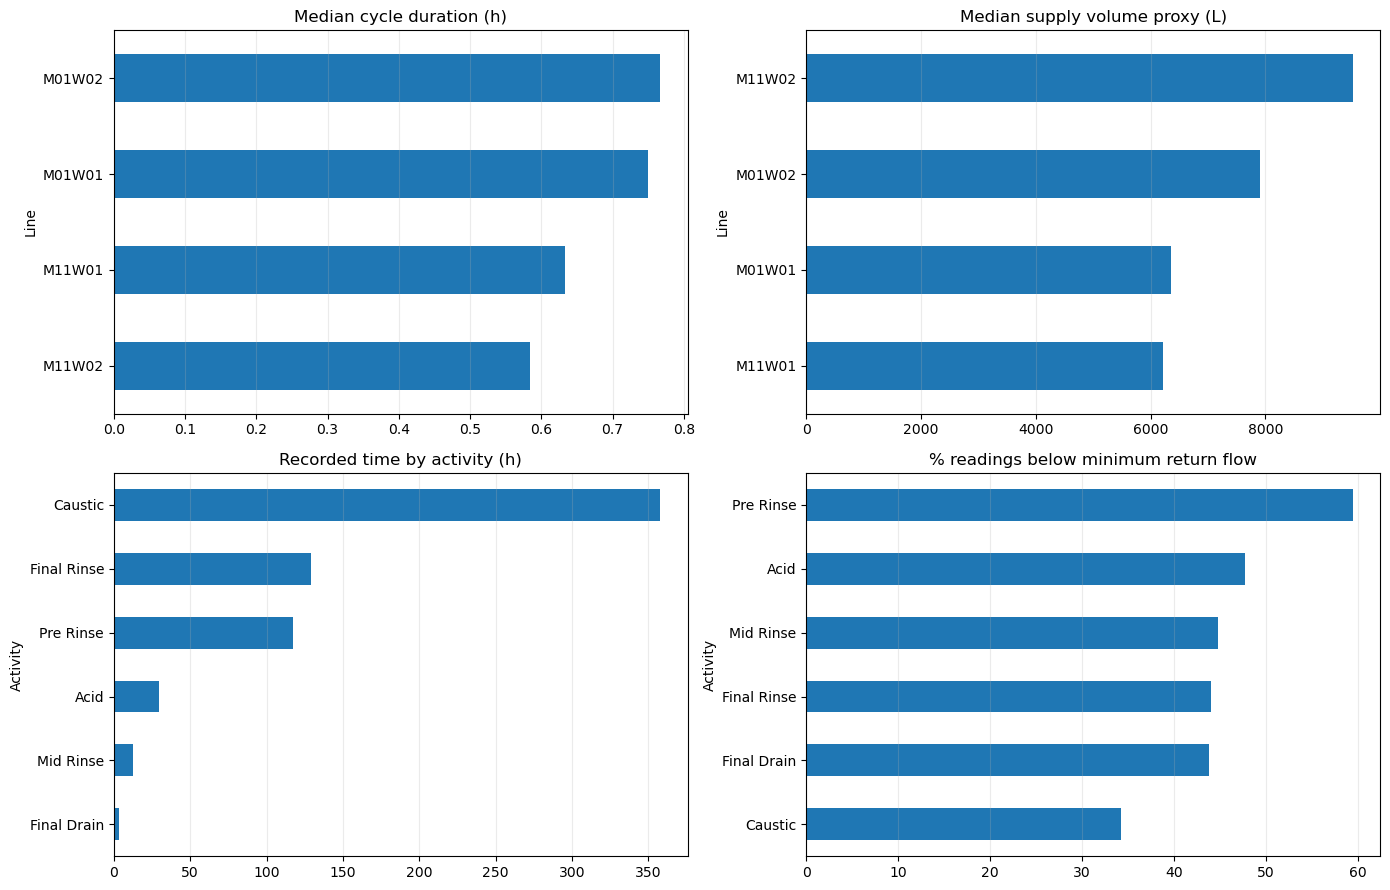

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
cycle_summary.groupby('Line')['duration_h'].median().sort_values().plot.barh(ax=axes[0, 0], title='Median cycle duration (h)')
cycle_summary.groupby('Line')['supply_volume_l_proxy'].median().sort_values().plot.barh(ax=axes[0, 1], title='Median supply volume proxy (L)')
data.groupby('Activity')['sample_seconds'].sum().div(3600).sort_values().plot.barh(ax=axes[1, 0], title='Recorded time by activity (h)')
data.groupby('Activity')['flow_margin'].apply(lambda s: (s < 0).mean() * 100).sort_values().plot.barh(ax=axes[1, 1], title='% readings below minimum return flow')
for ax in axes.flat:
    ax.grid(axis='x', alpha=.25)
plt.tight_layout()
plt.show()

## Candidate improvement checks

The table below ranks step/line combinations by estimated supply volume and time. These are investigation candidates, not automatic recommendations. Confirm cleaning validation, microbiological requirements, equipment geometry, and the true flow-meter units before changing a recipe.

In [12]:
candidates = step_summary.reset_index().copy()
candidates['volume_rank'] = candidates['supply_volume_l_proxy'].rank(ascending=False, method='min')
candidates['time_rank'] = candidates['duration_h'].rank(ascending=False, method='min')
candidates['review_score'] = candidates['volume_rank'] + candidates['time_rank']
candidates.sort_values(['review_score', 'supply_volume_l_proxy']).head(20)

,Line,Activity,Step,rows,cycles,duration_h,supply_volume_l_proxy,avg_temp_gap,avg_flow_margin,pct_below_min_flow,avg_return_conductivity,volume_rank,time_rank,review_score
1,M01W02,Caustic,Circulation,5690,151,94.87,"1,146,867.77",4.62,"1,676.27",26.66,63.76,2.00,1.00,3.00
0,M11W02,Caustic,Circulation,4701,271,78.35,"1,188,829.39",7.56,"1,264.99",20.91,102.53,1.00,3.00,4.00
2,M11W01,Caustic,Circulation,4936,250,82.27,"802,221.64",5.98,-843.34,31.77,98.56,3.00,2.00,5.00
3,M01W01,Caustic,Circulation,3086,109,51.43,"398,827.83",14.27,"-1,981.27",56.35,66.78,4.00,4.00,8.00
4,M11W02,Final Rinse,Circulation,1424,271,23.73,"351,827.54",46.23,-778.03,38.34,3.54,5.00,6.00,11.00
7,M11W01,Final Rinse,Circulation,1548,251,25.80,"231,460.81",45.92,"-3,058.28",51.10,6.89,8.00,5.00,13.00
5,M11W02,Pre Rinse,Circulation,1245,276,20.75,"285,898.22",42.48,"-2,130.41",43.53,8.20,6.00,7.00,13.00
6,M01W02,Final Rinse,Circulation,1125,151,18.75,"231,837.73",16.82,"1,924.82",36.89,3.23,7.00,8.00,15.00
9,M11W01,Pre Rinse,Circulation,1093,251,18.22,"156,144.09",39.88,"-4,298.07",67.98,7.91,10.00,9.00,19.00
10,M01W01,Final Rinse,Circulation,834,116,13.90,"147,622.31",53.33,730.88,49.76,5.54,11.00,10.00,21.00


### Limits of this first pass

The files do not provide chemical concentration, conductivity calibration, tank/pipe volume, valve state, drain destination, recovered-water volume, product carryover, or microbiological release results. Add those fields before converting these comparisons into savings, compliance, or recipe-change decisions.